In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import pandas as pd
import numpy as np


In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,Flatten,Dense

from skimage.io import imread
from skimage.transform import resize

In [ ]:
os.listdir('/content/drive/MyDrive/Mask data (1)')

['Mask_train', 'Mask_test']

In [ ]:
os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_train')

['without_mask', 'with_mask']

In [ ]:
os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_test')

['without_mask', 'with_mask']

In [ ]:
len(os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_test/with_mask'))

53

In [ ]:
len(os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_test/without_mask'))

53

In [ ]:
len(os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_train/with_mask'))

690

In [ ]:
len(os.listdir('/content/drive/MyDrive/Mask data (1)/Mask_train/without_mask'))

686

In [ ]:
xtrain = []
ytrain = []

In [ ]:
datadir = '/content/drive/MyDrive/Mask data (1)/Mask_train'

In [ ]:
categories = ['without_mask', 'with_mask']

In [ ]:
for i in categories:
  print(i)
  path = os.path.join(datadir,i)

  for img in os.listdir(path):
    img_path = os.path.join(path,img)

    img_read = imread(img_path)
    img_res = resize(img_read,(150,150,3))

    if img_res.shape != (150,150,3):
      print(img, img_res.shape)

    xtrain.append(img_res)
    ytrain.append(categories.index(i))



without_mask
with_mask


In [ ]:
print(img_read.shape)

(428, 320, 3)


In [ ]:
print(img, img_read.shape)

augmented_image_118.jpg (428, 320, 3)


In [ ]:
# testing

xtest = []
ytest = []

datadir1 = '/content/drive/MyDrive/Mask data (1)/Mask_test'
categories1 =  ['without_mask', 'with_mask']

In [ ]:
for j in categories1:
  print(j)
  path1 = os.path.join(datadir1,j)

  for imgs in os.listdir(path1):
    imgs_path = os.path.join(path1,imgs)

    img2 = imread(imgs_path)
    img2_res = resize(img2,(150,150,3))

    xtest.append(img2_res)
    ytest.append(categories1.index(j))

without_mask
with_mask


In [ ]:
xtrain = np.array(xtrain)
ytrain = np.array(ytrain)
xtest = np.array(xtest)
ytest = np.array(ytest)

In [ ]:
# from collections import Counter

# shapes = Counter([img.shape for img in xtest])

# print(shapes)

In [ ]:
model = Sequential()

In [ ]:
model.add(Conv2D(32,(3,3),activation='relu',input_shape=(150,150,3)))
# model.add(Conv2D(64,(3,3),activation='relu',input_shape=(150,150,3)))
# model.add(Conv2D(128,(3,3),activation='relu',input_shape=(150,150,3)))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.add(MaxPool2D(2,2))

In [ ]:
model.add(Flatten())

In [ ]:
model.add(Dense(50,activation='relu'))
model.add(Dense(20,activation='relu'))
model.add(Dense(2,activation='softmax'))

In [ ]:
model.compile(optimizer='adam',
              loss = 'sparse_categorical_crossentropy',
              metrics = ['accuracy'])

In [ ]:
model.fit(xtrain,ytrain,epochs=20 , batch_size = 60)

Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.5029 - loss: 0.6934
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.4782 - loss: 0.6935
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.4782 - loss: 0.6933
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.4826 - loss: 0.6935
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.5044 - loss: 0.6934
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.4985 - loss: 0.6933
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.4898 - loss: 0.6935
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 0.4826 - loss: 0.6934
Epoch 9/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.4898 - loss: 0.6935
Epoch 10/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.4811 - loss: 0.6934
Epoch 11/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.5015 - loss: 0.6933
Epoch 12/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.4840 - lo

array([[[248, 252, 229],
        [249, 251, 230],
        [255, 255, 243],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[252, 255, 244],
        [253, 255, 245],
        [255, 255, 250],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[240, 250, 252],
        [238, 247, 252],
        [243, 250, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]], shape=(428, 320, 3), dtype=uint8)
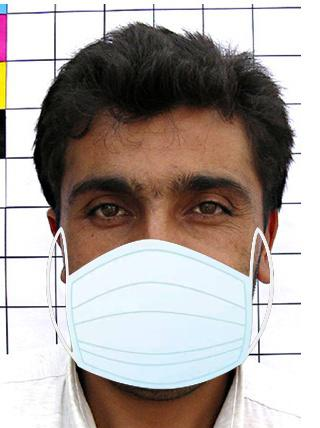

In [ ]:
img = '/content/drive/MyDrive/Mask data (1)/Mask_test/with_mask/103-with-mask.jpg'
img_read = imread(img)
img_read

In [ ]:
res = resize(img_read,(1,150,150,3))
pred = model.predict(res)
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step


array([[0.49390122, 0.5060988 ]], dtype=float32)

In [ ]:
predicted_class = np.argmax(pred,axis=1)
print(predicted_class)

[1]


array([[[184,  78, 116],
        [184,  78, 116],
        [184,  78, 116],
        ...,
        [193,  81, 121],
        [193,  81, 121],
        [193,  81, 119]],

       [[185,  79, 117],
        [185,  79, 117],
        [185,  79, 117],
        ...,
        [193,  81, 121],
        [193,  81, 121],
        [193,  81, 119]],

       [[185,  79, 117],
        [185,  79, 117],
        [185,  79, 117],
        ...,
        [193,  81, 121],
        [193,  81, 121],
        [193,  81, 119]],

       ...,

       [[222, 103, 131],
        [222, 103, 131],
        [225, 102, 131],
        ...,
        [ 15,  13,  14],
        [ 15,  13,  14],
        [ 16,  14,  17]],

       [[222, 103, 131],
        [222, 103, 131],
        [225, 102, 131],
        ...,
        [ 15,  13,  14],
        [ 15,  13,  14],
        [ 16,  14,  17]],

       [[222, 103, 131],
        [222, 103, 131],
        [225, 102, 131],
        ...,
        [ 15,  13,  14],
        [ 15,  13,  14],
        [ 17,  15,  18]]], shape=(224, 225, 3), dtype=uint8)
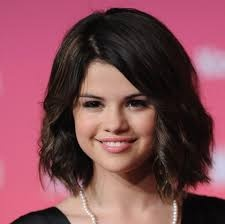

In [ ]:
img2 = '/content/drive/MyDrive/Mask data (1)/Mask_test/without_mask/11.jpg'
img2_read = imread(img2)
img2_read

In [ ]:
res2 = resize(img2_read,(1,150,150,3))
pred2 = model.predict(res2)
pred2

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


array([[0.49390122, 0.5060988 ]], dtype=float32)

In [ ]:
pred_class = np.argmax(pred2,axis=1)
pred_class

array([1])